# Benchmark Results

This notebook reproduces the benchmark figures from the paper. It evaluates three RL algorithms: **PPO**, **SAC**, **TD3** alongside three non-learning baselines: **FiPla**, **Constant**, **Random**  on the `survival-second-price-exponential` scenario (second-price auction, exponentially-distributed campaign horizon, survival value kernel).

See [`BENCHMARK.md`](BENCHMARK.md) for the full experimental protocol: scenario description, environment wrappers, training hyperparameters, and reproduction steps.

In [1]:
from benchmark.evaluate import run_full_benchmark, score_matrix, EvalConfig
from benchmark import plots
import pandas as pd

## 1. Run benchmark

Requires pretrained models in `benchmark/models/` (see `BENCHMARK.md § Pretrained Models`). Skip this cell and go to **Section 2** if you already have a saved CSV.

In [2]:
seeds = [i for i in range(100)]
run_full_benchmark(cfg=EvalConfig(seeds=seeds))

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


  Loaded PPO ← /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/models/ppo/best_model.zip
  Loaded SAC ← /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/models/sac/best_model.zip
  Loaded TD3 ← /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/models/td3/best_model.zip

Benchmarking 6 policies: ['PPO', 'SAC', 'TD3', 'FiPla', 'Constant(0.5)', 'Random']
  Evaluating PPO (100 seeds) …
  Evaluating SAC (100 seeds) …
  Evaluating TD3 (100 seeds) …
  Evaluating FiPla (100 seeds) …
  Evaluating Constant(0.5) (100 seeds) …
  Evaluating Random (100 seeds) …

Results saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/results/benchmark_results.csv


,policy,seed,step,t,reward,cum_reward,won,bid,payment,ctx,expected_reward,competing_bid
0,PPO,0,1,0.113466,0.0,0.000000,False,0.000000,0.0,1.000000,0.000000e+00,0.494734
1,PPO,1,1,1.906084,0.0,0.000000,False,0.000000,0.0,1.000000,1.000000e+00,0.256389
2,PPO,1,2,4.494624,0.0,0.000000,False,0.000000,0.0,1.000000,0.000000e+00,0.400601
3,PPO,1,3,4.522700,0.0,0.000000,False,0.000000,0.0,1.000000,0.000000e+00,22.198890
4,PPO,1,4,5.330860,0.0,0.000000,False,0.000000,0.0,1.000000,0.000000e+00,0.960951
...,...,...,...,...,...,...,...,...,...,...,...,...
25585,Random,99,135,132.036896,0.0,-11.321674,False,0.115146,0.0,0.000039,7.677583e-06,8.127128
25586,Random,99,136,134.077057,0.0,-11.321674,False,0.883274,0.0,0.000039,0.000000e+00,2.464143
25587,Random,99,137,134.636353,0.0,-11.321674,False,0.414826,0.0,0.000039,0.000000e+00,0.595901
25588,Random,99,138,134.970459,0.0,-11.321674,False,0.387274,0.0,0.000039,7.378975e-07,1.181344


## 2. Load results

Load the saved per-step CSV and build the score matrix (total episode reward per policy per seed) used by rliable.

In [3]:
df = pd.read_csv("results/benchmark_results.csv")
scores = score_matrix(df)

Mean number of auction opportunities per episode across all seeds. The horizon is exponentially distributed with rate η, giving a mean campaign length of 1/η auctions.

In [4]:
# list of horizons per seed
pd.DataFrame(df.groupby("seed")["t"].transform("max").unique()).mean()

0    40.186722
dtype: float64

## 3. Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across 30 seeds, with stratified bootstrap confidence intervals (rliable). Lower variance in IQM makes it a more reliable aggregate than mean for small seed counts.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/aggregate_metrics.pdf


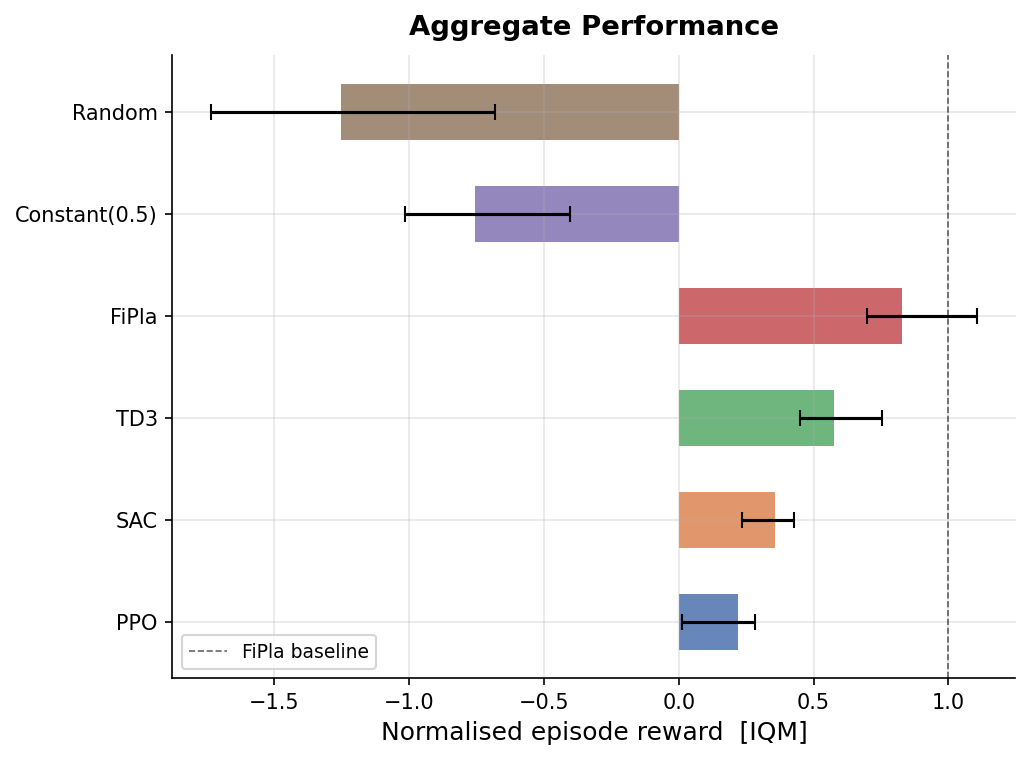

In [4]:
_ = plots.plot_aggregate_metrics(scores)

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance across seeds.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/performance_profiles.pdf


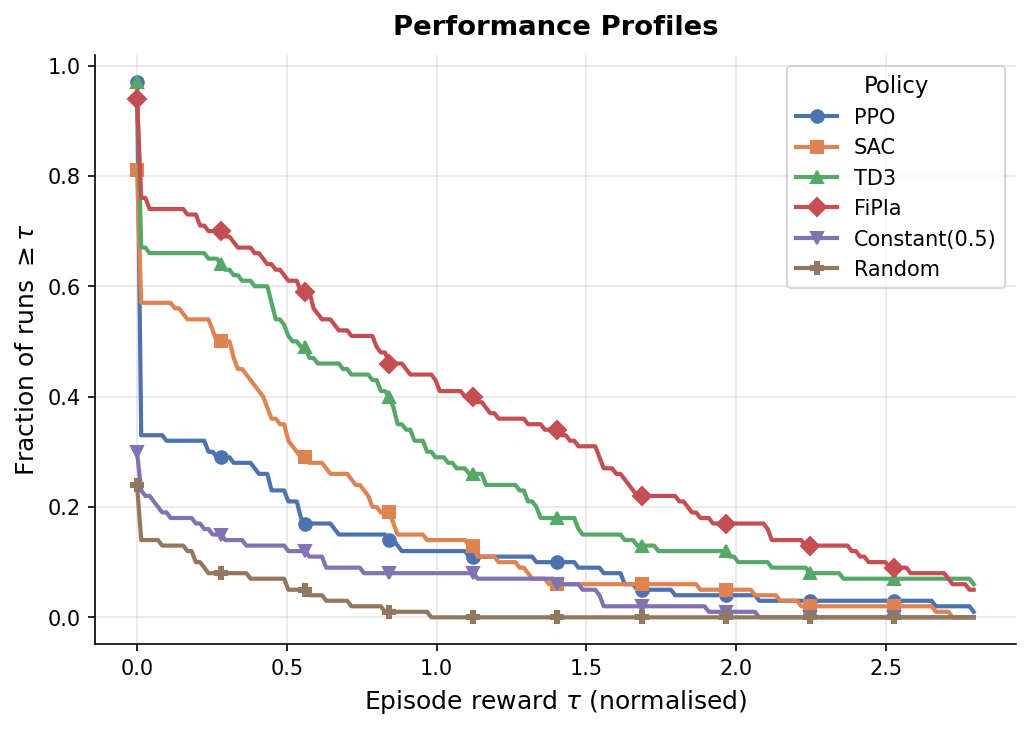

In [5]:
_ = plots.plot_performance_profiles(scores)

### Cumulative reward over time

Mean cumulative reward as a function of auction step, averaged over 30 seeds. Shaded bands are ±1 standard deviation.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/cumulative_reward.pdf


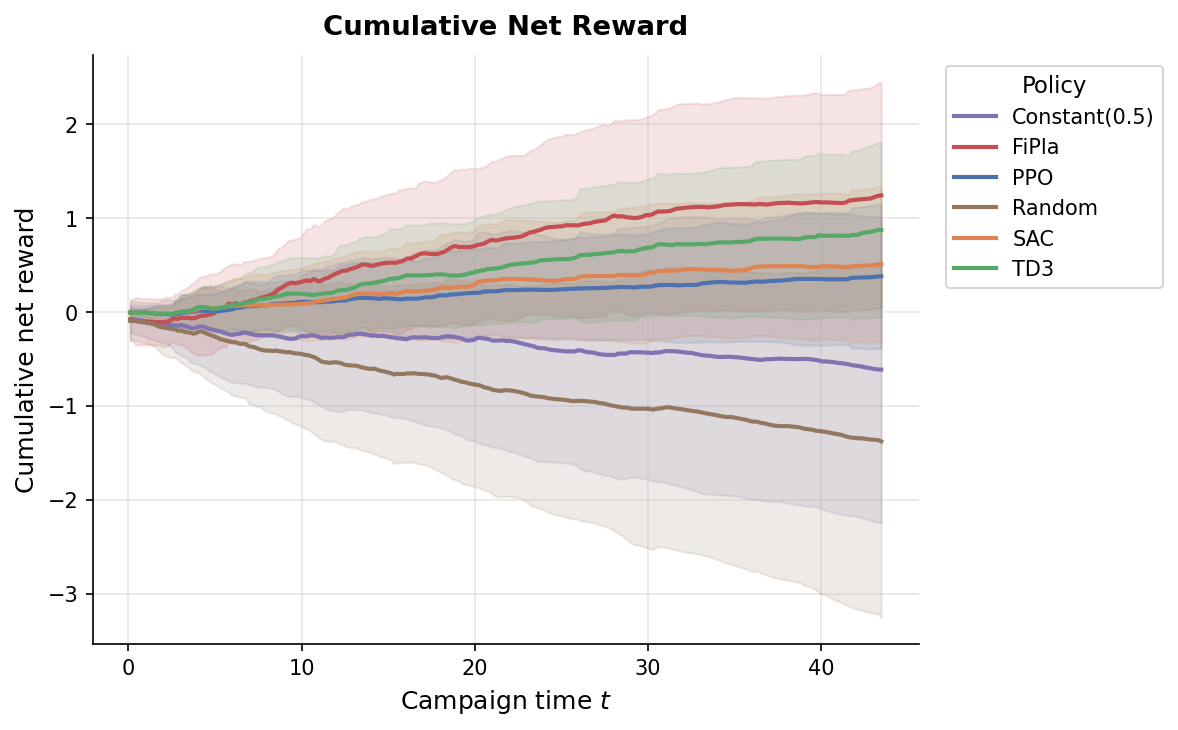

In [6]:
_ = plots.plot_cumulative_reward(df)

### Episode reward distribution

Distribution of total episode reward across 30 seeds for each policy (violin + individual seed points).

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:264: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/reward_distribution.pdf


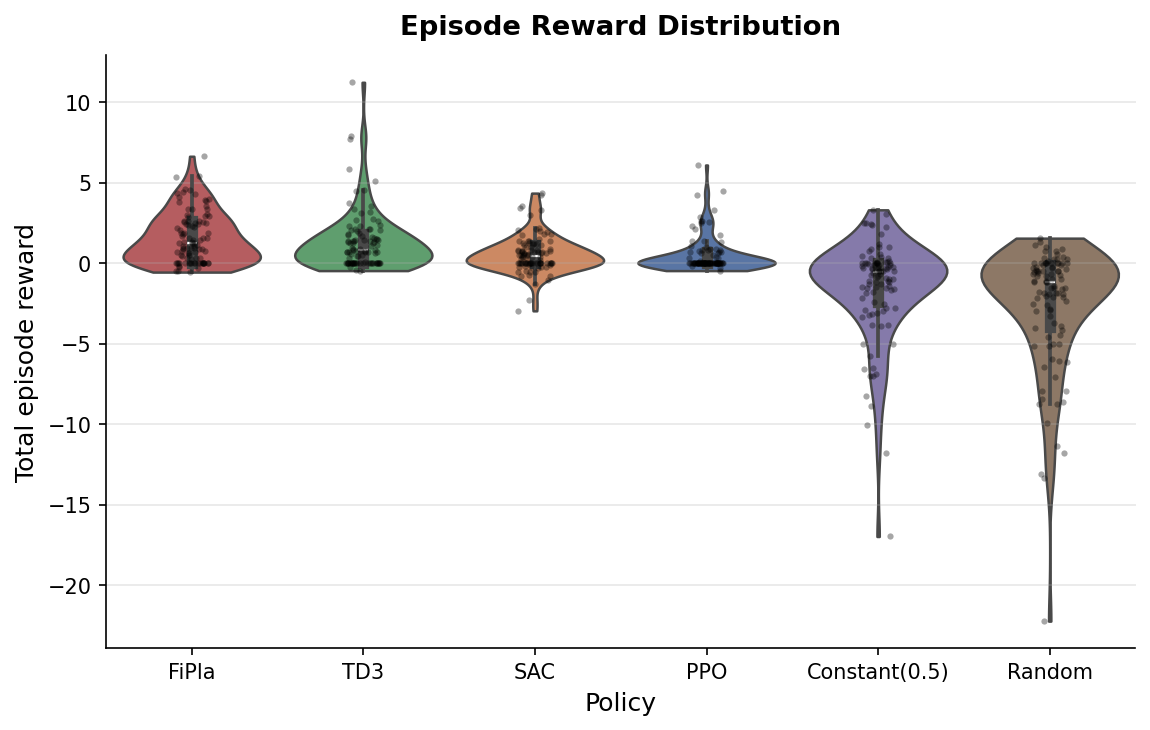

In [7]:
_ = plots.plot_reward_distribution(df)

### Training curves

Mean episodic reward during training (from TensorBoard logs), smoothed over a rolling window. One curve per RL algorithm; baselines are not trained so they do not appear here.

  [WARNING] Tag 'eval/mean_reward' not found for SAC
  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/training_curves.pdf


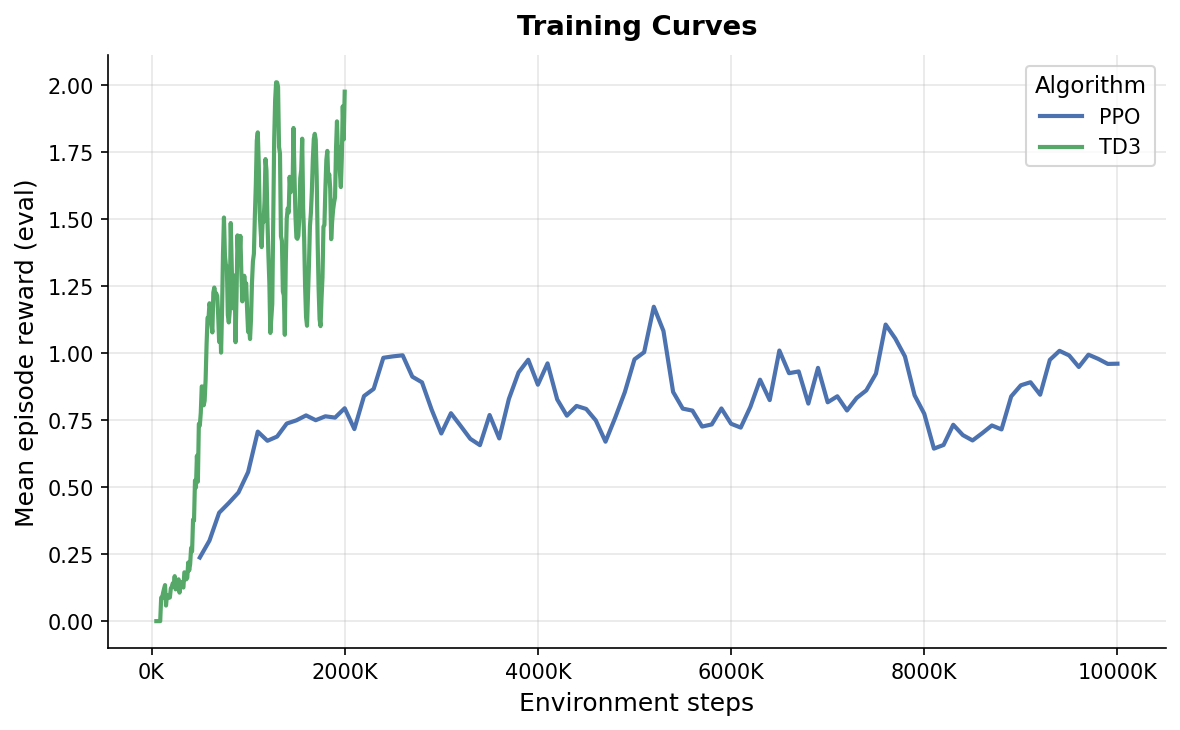

In [8]:
_ = plots.plot_training_curves()

### Context dynamics

Evolution of the context signal `ctx` over auction steps, averaged across seeds. Illustrates how the survival/saturation value kernel erodes the display value as the campaign progresses.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/context_dynamics.pdf


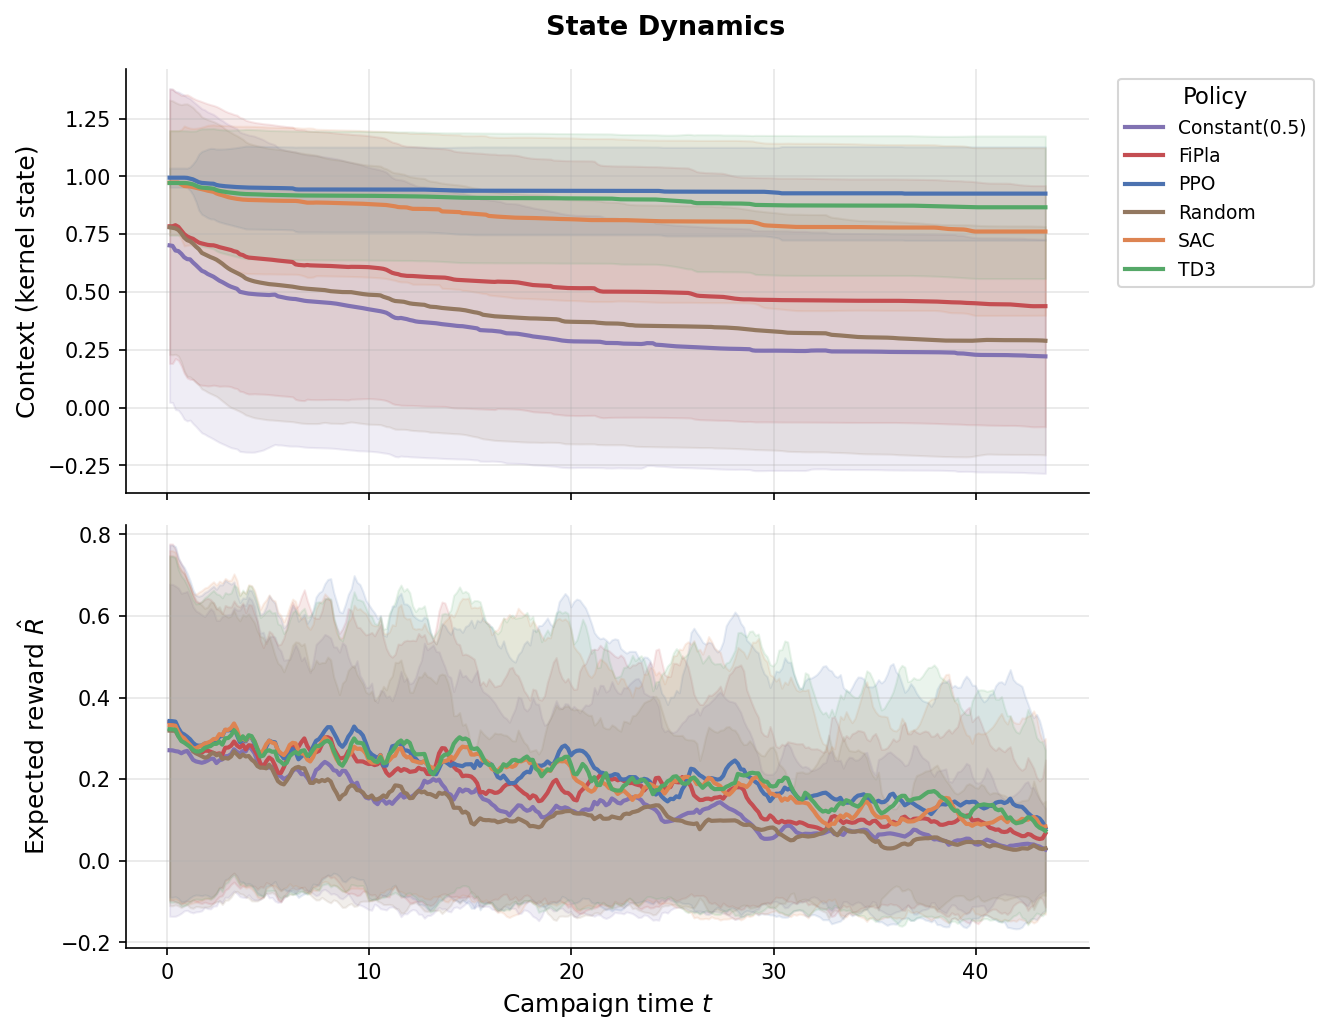

In [9]:
_ = plots.plot_context_dynamics(df)

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`). Shows how well each policy aligns bids with true value.

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:445: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(bids, ax=ax, color=color, lw=2,


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/bid_distributions.pdf


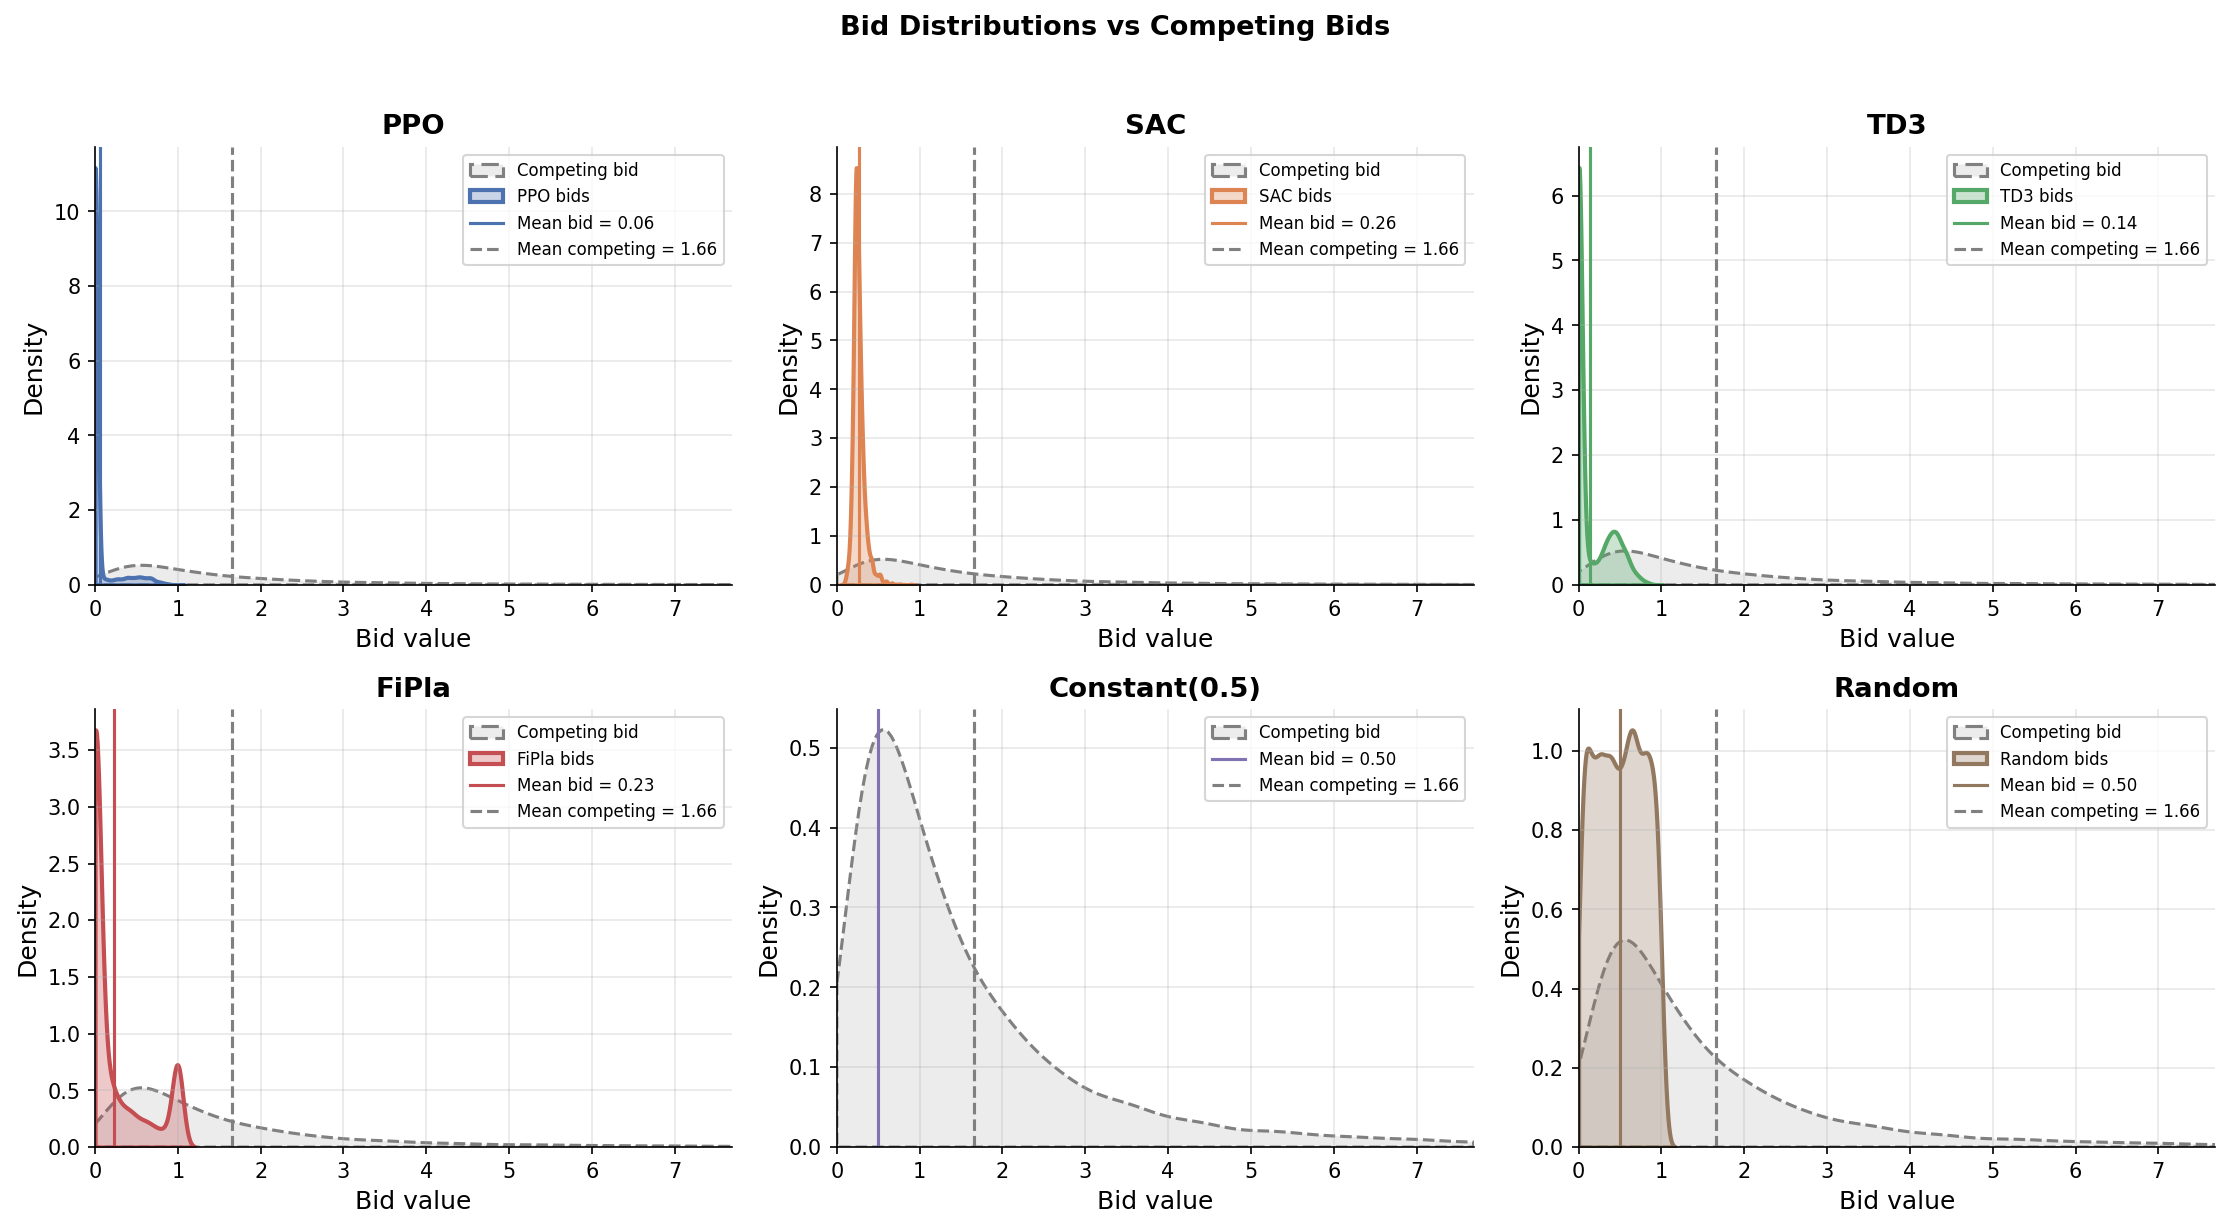

In [10]:
_ = plots.plot_bid_distributions(df)

### Win rate

Fraction of auctions won per policy, averaged over seeds. Under second-price rules the truthful bid (FiPla) is optimal, so its win rate serves as the upper reference.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/win_rate.pdf


/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:488: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",


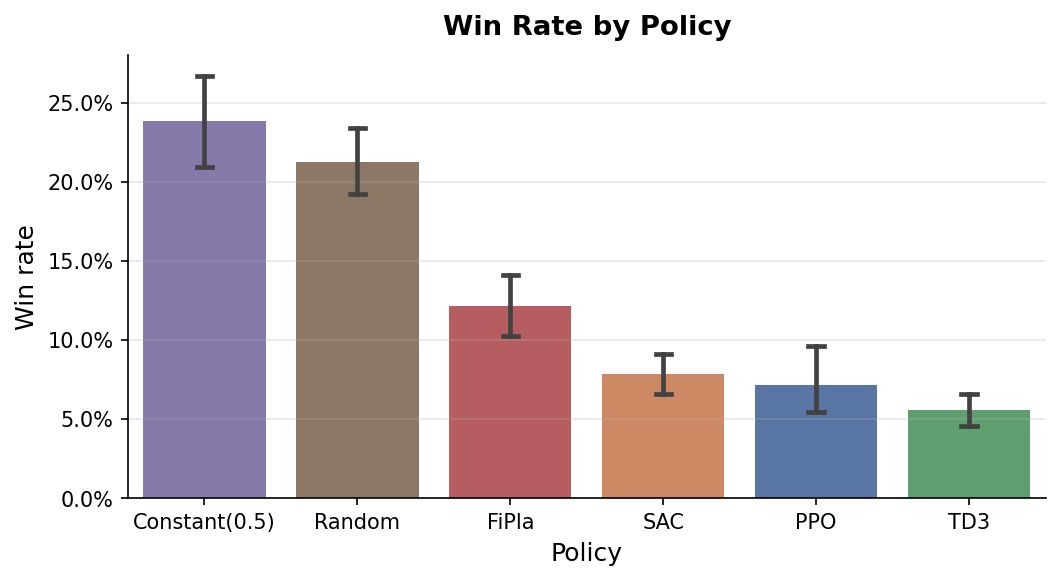

In [26]:
_ = plots.plot_win_rate(df)

### Full benchmark summary

Combined figure reported in the paper, aggregating aggregate metrics, performance profiles, and reward distributions into a single panel.

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:598: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/full_benchmark.pdf


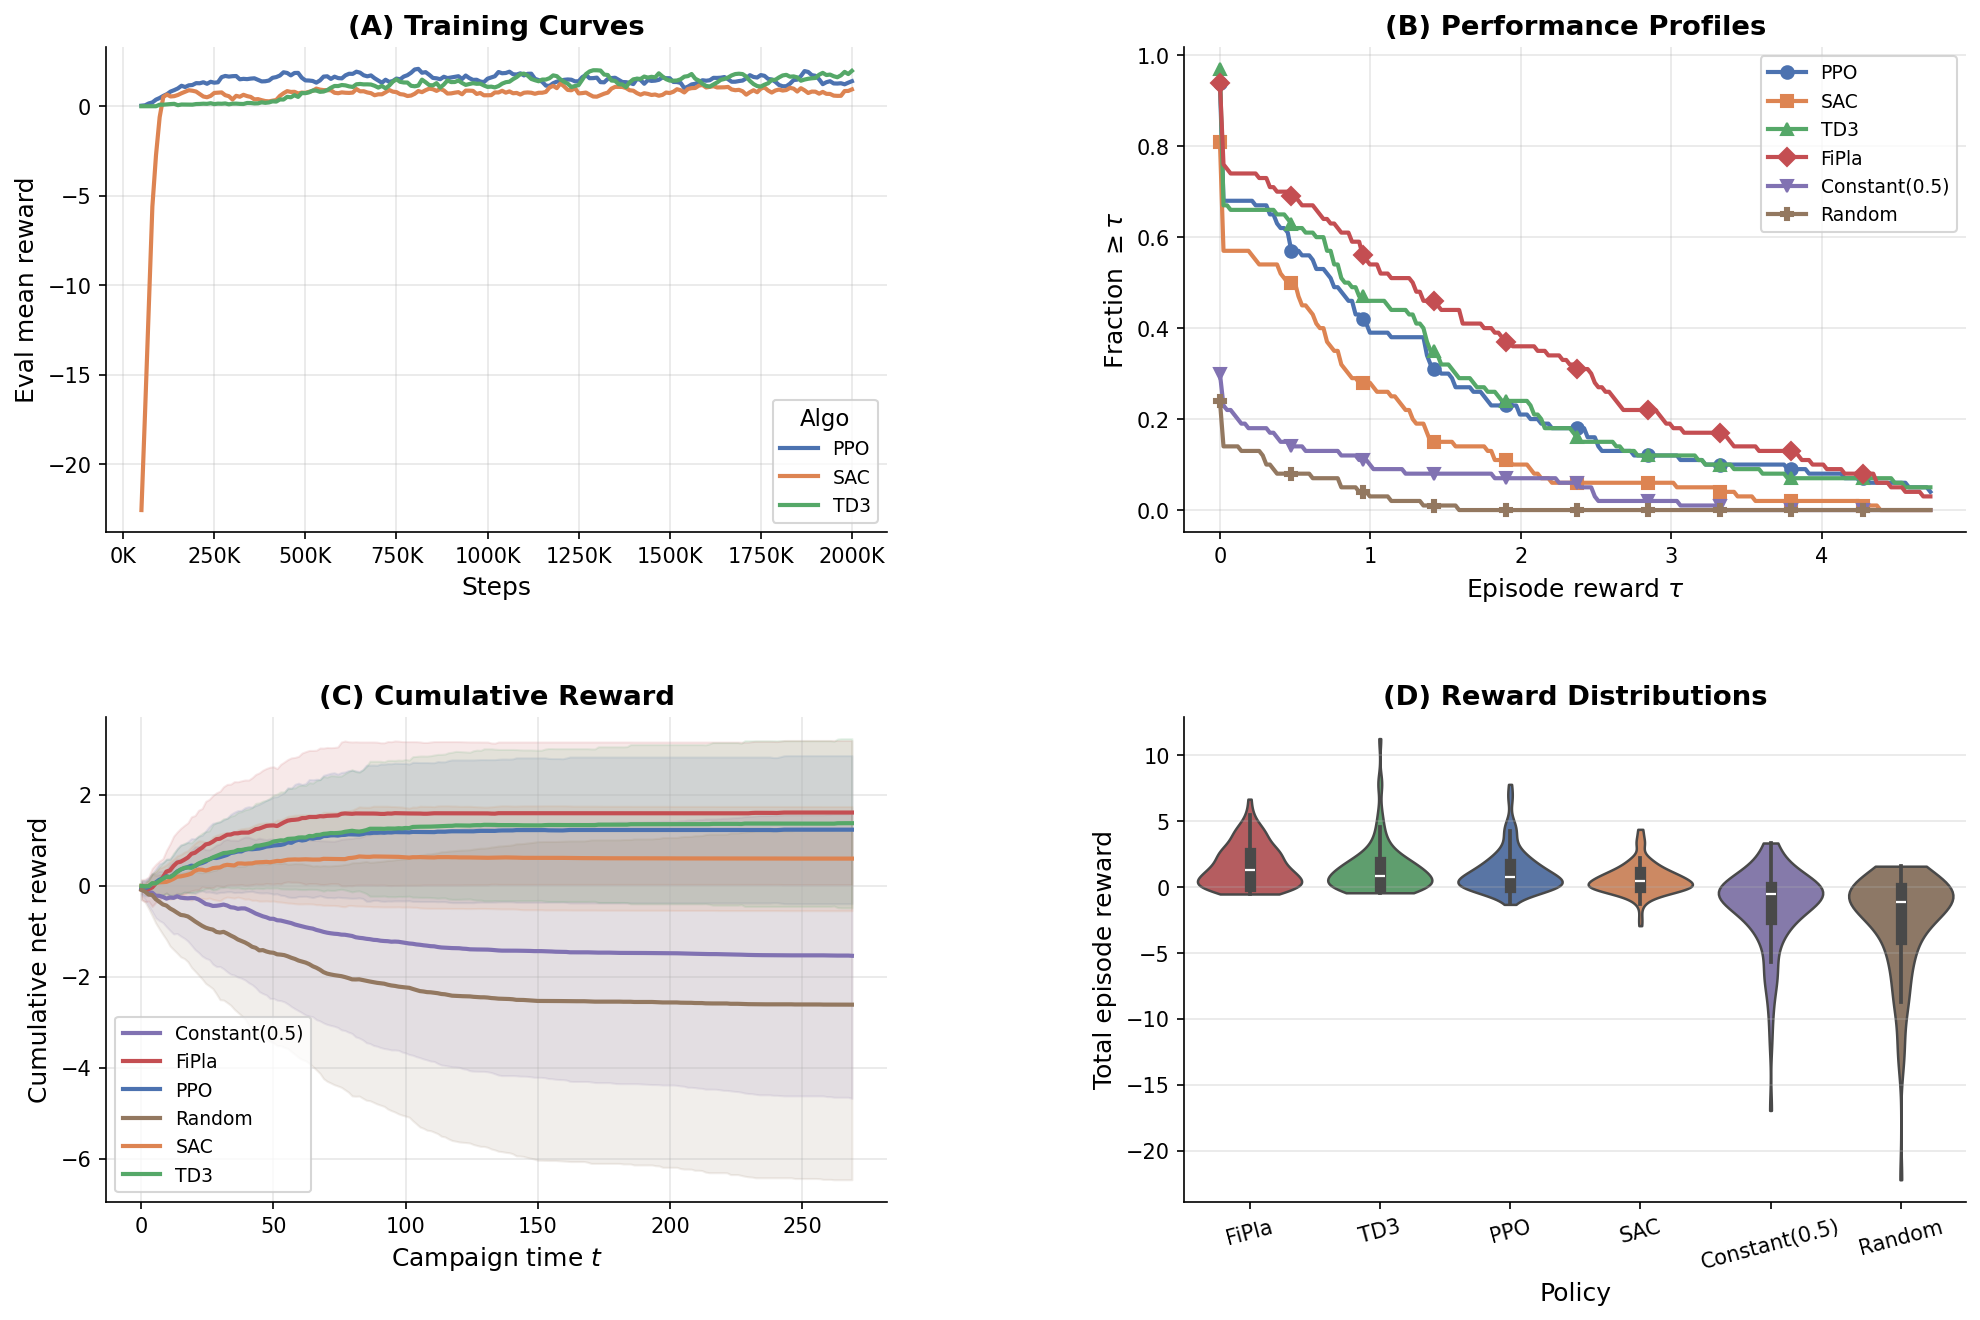

In [27]:
_ = plots.plot_full_benchmark(df, scores)